        Y     X1     X2     X3
Y  1.0000 0.9944 0.9977 0.9993
X1 0.9944 1.0000 0.9918 0.9924
X2 0.9977 0.9918 1.0000 0.9964
X3 0.9993 0.9924 0.9964 1.0000



Call:
lm(formula = Y ~ X1 + X2 + X3, data = data)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.43729 -0.17204  0.02947  0.12097  0.57162 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  10.2406     5.4897   1.865   0.0890 .  
X1            0.6354     0.3065   2.073   0.0624 .  
X2            0.3208     0.1351   2.374   0.0369 *  
X3            0.7245     0.1101   6.579 3.98e-05 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.3043 on 11 degrees of freedom
Multiple R-squared:  0.9994,	Adjusted R-squared:  0.9992 
F-statistic:  5711 on 3 and 11 DF,  p-value: < 2.2e-16


(Intercept)          X1          X2          X3 
 10.2405757   0.6353667   0.3207676   0.7244688

R-squared    : 0.9994 
Adj R-squared: 0.9992 
F hitung     : 5710.8 


,Df,Sum Sq,Mean Sq,F value,Pr(>F)
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
X1,1,1569.550439,1.569550e+03,16951.3560,6.870556e-19
X2,1,12.757254,1.275725e+01,137.7801,1.459138e-07
X3,1,4.007135,4.007135e+00,43.2776,3.977832e-05
Residuals,11,1.018506,9.259144e-02,NA,NA


Prediksi nilai akhir: 74.16 


,fit,lwr,upr
1,74.16175,73.68102,74.64249


,fit,lwr,upr
1,74.16175,73.33734,74.98617


    X1     X2     X3 
 71.95 152.01 163.90 


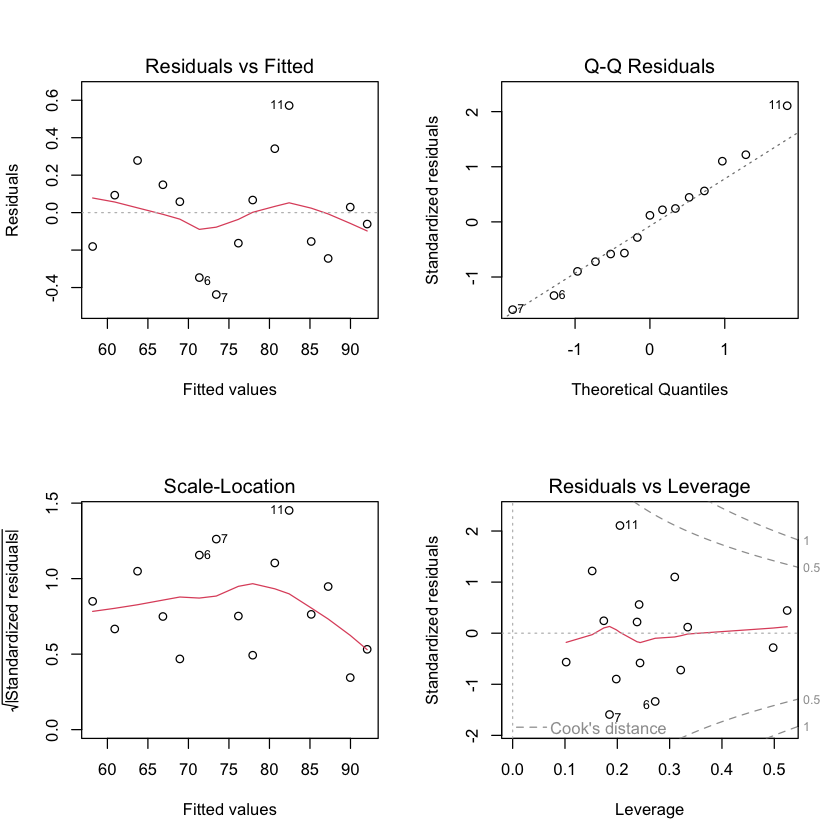

In [ ]:

# 1. Data
data <- data.frame(
  No = 1:15,
  X1 = c(3,4,4,5,5,6,6,7,7,8,8,9,9,10,10),                    # Jam belajar mandiri
  X2 = c(8,10,12,13,15,16,18,20,21,23,24,26,28,30,32),         # Jumlah akses tuton
  X3 = c(60,62,65,68,70,72,74,76,78,80,82,84,86,88,90),        # Nilai tugas tutorial
  Y  = c(58,61,64,67,69,71,73,76,78,81,83,85,87,90,92)         # Nilai akhir
)

# 2. Korelasi (soal 4 dan 8)
print(round(cor(data[, c("Y","X1","X2","X3")]), 4))

# 3. Model regresi berganda (soal 5 dan 6)
model <- lm(Y ~ X1 + X2 + X3, data = data)
summary(model)          # koefisien, SE, uji t, R-squared, uji F
coef(model)             # a, b1, b2, b3

# Uji F keseluruhan dan R-squared
s <- summary(model)
cat("R-squared    :", round(s$r.squared, 4), "\n")
cat("Adj R-squared:", round(s$adj.r.squared, 4), "\n")
cat("F hitung     :", round(s$fstatistic[1], 2), "\n")

# Tabel ANOVA
anova(model)

# 4. Prediksi (soal 7)
baru <- data.frame(X1 = 6, X2 = 18, X3 = 75)
pred <- predict(model, newdata = baru)
cat("Prediksi nilai akhir:", round(pred, 2), "\n")

# Dengan selang kepercayaan/prediksi 95%
predict(model, newdata = baru, interval = "confidence")
predict(model, newdata = baru, interval = "prediction")

# 5. Multikolinearitas: VIF (soal 8), dihitung manual
vif_manual <- function(var, others) {
  r2 <- summary(lm(reformulate(others, response = var), data = data))$r.squared
  1 / (1 - r2)
}
vif <- c(
  X1 = vif_manual("X1", c("X2","X3")),
  X2 = vif_manual("X2", c("X1","X3")),
  X3 = vif_manual("X3", c("X1","X2"))
)
print(round(vif, 2))     # VIF > 10 berarti multikolinearitas serius

# (Alternatif jika paket car terpasang)
# install.packages("car"); library(car); vif(model)

# 6. Diagnostik residual (opsional)
par(mfrow = c(2, 2))
plot(model)
par(mfrow = c(1, 1))